# Project 02: Data Visualization with Matplotlib & Seaborn

**Dataset:** the `tips` dataset (restaurant bills, tips, day, time, party size, smoker).

## Four questions
1. How are bills distributed? *(histogram)*
2. Do tips differ by day? *(box plot)*
3. Does a bigger bill mean a bigger tip? *(scatter plot)*
4. Which numbers move together? *(correlation heatmap)*

Two extra bar charts then check the tip rate and party size.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# One colour-blind-friendly palette used throughout (no red/green pairs)
sns.set_theme(style="whitegrid", palette="colorblind")

tips = sns.load_dataset("tips")
tips["day"] = pd.Categorical(tips["day"], ["Thur", "Fri", "Sat", "Sun"], ordered=True)
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100
print(tips.shape)
tips.head()

(244, 8)


,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


## Why each chart type
| Question | Chart | Why |
|---|---|---|
| One number (bill) | Histogram | Shows the shape and spread of a single variable |
| Compare groups (tip by day) | Box plot | Shows median and spread for each group side by side |
| Two numbers (bill vs tip) | Scatter plot | Shows whether two numbers rise together |
| Many numbers | Heatmap of correlations | Shows every pair at once |

## Chart 1: the 2 x 2 overview

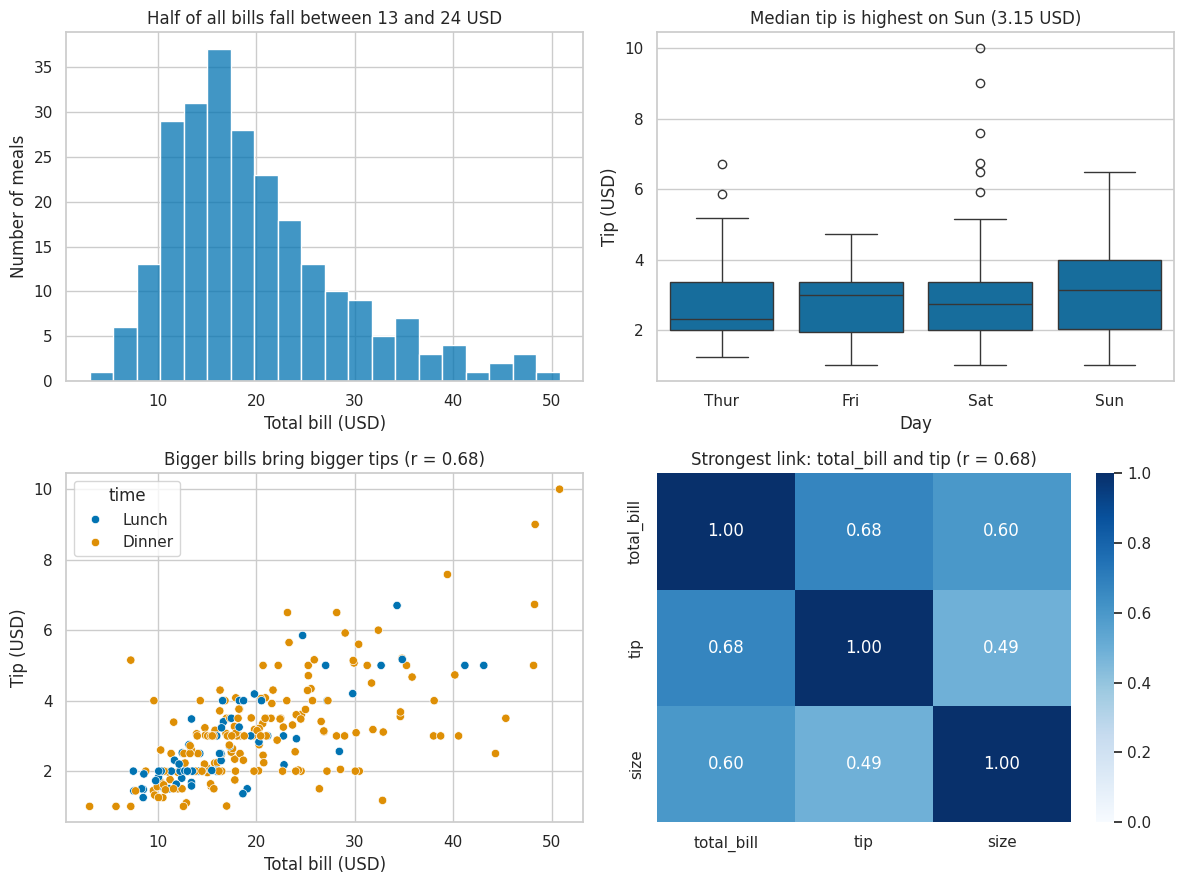

In [2]:
# Numbers used in the chart titles, so each title states a finding
q1, q3 = tips["total_bill"].quantile([0.25, 0.75])
med_by_day = tips.groupby("day", observed=True)["tip"].median()
best_day = med_by_day.idxmax()
r = tips["total_bill"].corr(tips["tip"])

corr = tips.select_dtypes("number").drop(columns="tip_pct").corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top_pair = pairs.abs().idxmax()
top_r = corr.loc[top_pair]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(tips["total_bill"], bins=20, ax=axes[0, 0])
axes[0, 0].set(title=f"Half of all bills fall between {q1:.0f} and {q3:.0f} USD",
               xlabel="Total bill (USD)", ylabel="Number of meals")

sns.boxplot(data=tips, x="day", y="tip", color=sns.color_palette()[0], ax=axes[0, 1])
axes[0, 1].set(title=f"Median tip is highest on {best_day} ({med_by_day[best_day]:.2f} USD)",
               xlabel="Day", ylabel="Tip (USD)")

sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", ax=axes[1, 0])
axes[1, 0].set(title=f"Bigger bills bring bigger tips (r = {r:.2f})",
               xlabel="Total bill (USD)", ylabel="Tip (USD)")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title(f"Strongest link: {top_pair[0]} and {top_pair[1]} (r = {top_r:.2f})")

plt.tight_layout()
plt.savefig("tips_overview.png", dpi=150)
plt.show()

### Takeaways for Chart 1

In [3]:
display(Markdown(f"""
- **Histogram:** half of the {len(tips)} bills fall between **${q1:.2f}** and **${q3:.2f}**; the median bill is **${tips['total_bill'].median():.2f}**, and a few large bills stretch the right tail.
- **Box plot:** the median tip is highest on **{best_day}** (${med_by_day[best_day]:.2f}), but the boxes overlap a lot, so the differences between days are small compared with the spread within each day.
- **Scatter plot:** tips rise with the bill (correlation **{r:.2f}**), and lunch and dinner follow the same pattern.
- **Heatmap:** the strongest relationship is between **{top_pair[0]}** and **{top_pair[1]}** (**{top_r:.2f}**). Colour intensity shows strength; every value here is positive.
"""))


- **Histogram:** half of the 244 bills fall between **$13.35** and **$24.13**; the median bill is **$17.80**, and a few large bills stretch the right tail.
- **Box plot:** the median tip is highest on **Sun** ($3.15), but the boxes overlap a lot, so the differences between days are small compared with the spread within each day.
- **Scatter plot:** tips rise with the bill (correlation **0.68**), and lunch and dinner follow the same pattern.
- **Heatmap:** the strongest relationship is between **total_bill** and **tip** (**0.68**). Colour intensity shows strength; every value here is positive.


## Chart 2: the tip rate and party size (bar charts)

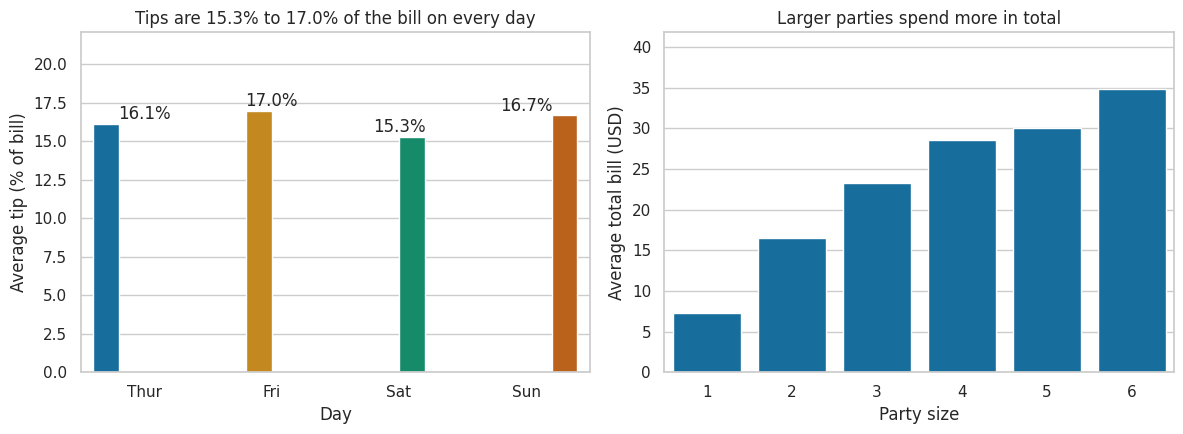

In [4]:
rate_by_day = tips.groupby("day", observed=True)["tip_pct"].mean()
bill_by_size = tips.groupby("size")["total_bill"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(x=rate_by_day.index, y=rate_by_day.values, hue=rate_by_day.index, legend=False, ax=axes[0])
axes[0].set(title=f"Tips are {rate_by_day.min():.1f}% to {rate_by_day.max():.1f}% of the bill on every day",
            xlabel="Day", ylabel="Average tip (% of bill)", ylim=(0, rate_by_day.max() * 1.3))
for i, v in enumerate(rate_by_day.values):
    axes[0].text(i, v + 0.3, f"{v:.1f}%", ha="center")

sns.barplot(x=bill_by_size.index, y=bill_by_size.values, color=sns.color_palette()[0], ax=axes[1])
axes[1].set(title="Larger parties spend more in total",
            xlabel="Party size", ylabel="Average total bill (USD)", ylim=(0, bill_by_size.max() * 1.2))

plt.tight_layout()
plt.savefig("tips_bar_charts.png", dpi=150)
plt.show()

### Takeaways for Chart 2

In [5]:
display(Markdown(f"""
- **Tip rate by day:** people tip about **{rate_by_day.mean():.0f}%** on every day, so the day of the week barely changes how generously people tip. Bars start at zero so the differences are not exaggerated.
- **Party size:** the average bill rises from **${bill_by_size.min():.0f}** for the smallest group to **${bill_by_size.max():.0f}** for the largest.
"""))


- **Tip rate by day:** people tip about **16%** on every day, so the day of the week barely changes how generously people tip. Bars start at zero so the differences are not exaggerated.
- **Party size:** the average bill rises from **$7** for the smallest group to **$35** for the largest.


## Honesty review
- [x] Bar charts start at zero; no axis is cut off.
- [x] Every chart has a title that states the finding, labelled axes and units.
- [x] One colour-blind-friendly palette (`colorblind`) is used throughout, and no red/green pairs appear.
- [x] The heatmap is annotated, with a fixed 0 to 1 colour scale so strength is not exaggerated.
- [x] `plt.tight_layout()` is used so labels are not cut off.
- [x] No 3D or pie charts.

**Saved images:** `tips_overview.png` (the 2 x 2 dashboard, 150 dpi) and `tips_bar_charts.png`.